# Com poucos posts em cada canal, em qual canal apostar, e quanto custa decidir cedo demais?

Uma operação de cortes de vídeo publica em seis canais: três nichos (Games, Negócios, Ciência) em duas plataformas (TikTok e YouTube). Cada canal tem de 8 a 12 posts com métrica. A média crua de cada canal engana quando a amostra é pequena; este notebook estima o desempenho de cada canal de três formas, mede o quanto a conclusão depende das escolhas do analista e simula o custo de decidir cedo.

O núcleo (amostrador de Gibbs com um passo de Metropolis, diagnósticos de convergência, amostragem de Thompson) está implementado em NumPy/SciPy no pacote `bayes_canais`, com testes contra casos de resposta conhecida em `tests/`. Aqui só se chama o pacote e se lê o resultado.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from bayes_canais import analise, dados, roteiro

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)

r = roteiro.executar()   # o mesmo roteiro e as mesmas sementes de scripts/rodar_analise.py
figuras = roteiro.figuras(r)
plt.close("all")         # cada figura é mostrada na seção em que é discutida
r["amostra"]

{'posts': 64,
 'cortes': 35,
 'canais': 6,
 'posts_maduros': 42,
 'posts_jovens': 22,
 'posts_com_zero_views': 2,
 'coletas': 2,
 'coleta_usada': '2026-11-10',
 'primeiro_post': '2026-11-07T18:00:00',
 'ultimo_post': '2026-11-10T09:00:00',
 'posts_por_canal_minimo': 8,
 'posts_por_canal_maximo': 12}

## 1. Os dados e a linha de base

Uma linha por post, na coleta mais recente. A linha de base é o que qualquer um faria: a média de views de cada canal.

In [2]:
crua = r["media_crua"]
display(crua[["posts", "posts_jovens", "media_de_views", "mediana_de_views", "maior_post", "parcela_do_maior_post", "posicao_pela_media_crua"]])

,posts,posts_jovens,media_de_views,mediana_de_views,maior_post,parcela_do_maior_post,posicao_pela_media_crua
canal,,,,,,,
TikTok · Games,12,6,447.33,539.50,859,0.16,3
TikTok · Negócios,12,4,490.58,526.50,1139,0.19,2
TikTok · Ciência,10,2,422.20,488.00,578,0.14,4
YouTube · Games,11,5,505.27,158.00,1662,0.30,1
YouTube · Negócios,11,4,156.91,4.00,1196,0.69,5
YouTube · Ciência,8,1,42.88,3.50,311,0.91,6


Pela média crua, o melhor canal seria o YouTube · Games. Só que a mediana dele é menos de um terço da média, e nos outros dois canais do YouTube um único post responde pela maior parte da soma. A média crua, com tão poucos posts, mede o maior post de cada canal.

A tabela seguinte mostra a mediana por dia de publicação. O YouTube · Games mudou de patamar em um dia: é o tipo de coisa que nenhum modelo de média fixa enxerga, e fica registrado como limitação.

In [3]:
display(r["lote_por_dia"])

dia,2026-11-07,2026-11-08,2026-11-09,2026-11-10
canal,,,,
TikTok · Games,433.50,360.00,616.00,60.00
TikTok · Negócios,406.50,514.00,597.00,33.00
TikTok · Ciência,350.00,503.00,483.00,NaN
YouTube · Games,132.50,25.50,"1,181.00",0.00
YouTube · Negócios,19.00,167.50,3.00,1.00
YouTube · Ciência,1.50,10.00,4.00,NaN


### Posts jovens: o número ainda vai subir

As duas coletas, com cerca de 13 horas entre elas, mostram quanto as views de um mesmo post cresceram conforme a idade que ele tinha na primeira.

In [4]:
display(r["crescimento"])
tabela = r["tabela"]
print("posts com 24 h ou mais (valor final):", int((~tabela["jovem"]).sum()))
print("posts de 12 a 24 h (entre o observado e 5x):", int(np.isfinite(tabela["teto"]).sum()))
print("posts com menos de 12 h (só piso):", int((tabela["jovem"] & ~np.isfinite(tabela["teto"])).sum()))

,posts,fator_mediano,fator_p90,fator_maximo,cresceram_mais_de_10_por_cento
faixa,,,,,
menos de 12 h,16,1.76,8.08,"1,191.00",0.69
12 a 24 h,4,1.00,1.65,1.93,0.25
24 h ou mais,38,1.00,1.06,3.06,0.05


posts com 24 h ou mais (valor final): 42
posts de 12 a 24 h (entre o observado e 5x): 18
posts com menos de 12 h (só piso): 4


Quem já tinha 24 horas quase não muda. Daí o tratamento: `y = log(1 + views)`; post com 24 horas ou mais entra com o valor observado; post de 12 a 24 horas entra como "entre o observado e 5 vezes o observado" (o maior crescimento visto depois de 12 horas foi de 3,1 vezes; 5 é folga); post com menos de 12 horas entra só como piso. No amostrador, o valor final desses posts é sorteado a cada passo de uma normal truncada (aumento de dados). A seção 5 mostra o quanto a conclusão depende dessa escolha.

## 2. Três formas de estimar o desempenho de cada canal

- **Sem agrupamento:** cada canal sozinho, com a sua média e a sua dispersão.
- **Agrupamento total:** uma média só para os seis.
- **Hierárquico (agrupamento parcial):** cada canal tem a sua média, mas as médias dos canais de uma plataforma vêm de uma distribuição comum, com desvio `tau`. Quanto menos dado o canal tem e quanto menor `tau`, mais a estimativa dele é puxada para a média da plataforma.

As três usam a mesma verossimilhança e o mesmo amostrador; muda só o que é compartilhado. O "post típico" é `exp(theta) - 1`: a mediana das views, não a média.

Sem agrupamento (cada canal sozinho)                  \
                                                 tipico tipico_inferior   
canal                                                                     
TikTok · Games                                   548.00          330.00   
TikTok · Negócios                                460.00          229.00   
TikTok · Ciência                                 437.00          331.00   
YouTube · Games                                  130.00           17.00   
YouTube · Negócios                                26.00            6.00   
YouTube · Ciência                                  7.00            1.00   

                                   Hierárquico (agrupamento parcial)  \
                   tipico_superior                            tipico   
canal                                                                  
TikTok · Games              973.00                            514.00   
TikTok · Negócios           944.00                            473.00   
TikTok · Ciência            598.00                            474.00   
YouTube · Games           1,078.00                             41.00   
YouTube · Negócios          112.00                             31.00   
YouTube · Ciência            29.00                             25.00   

                                                    \
                   tipico_inferior tipico_superior   
canal                                                
TikTok · Games              345.00          827.00   
TikTok · Negócios           308.00          713.00   
TikTok · Ciência            303.00          729.00   
YouTube · Games              13.00          172.00   
YouTube · Negócios            9.00           96.00   
YouTube · Ciência             5.00           84.00   

                   Agrupamento total (todos iguais)                  \
                                             tipico tipico_inferior   
canal                                                                 
TikTok · Games                               146.00           81.00   
TikTok · Negócios                            146.00           81.00   
TikTok · Ciência                             146.00           81.00   
YouTube · Games                              146.00           81.00   
YouTube · Negócios                           146.00           81.00   
YouTube · Ciência                            146.00           81.00   

                                    
                   tipico_superior  
canal                               
TikTok · Games              266.00  
TikTok · Negócios           266.00  
TikTok · Ciência            266.00  
YouTube · Games             266.00  
YouTube · Negócios          266.00  
YouTube · Ciência           266.00

,theta_sem_agrupamento,theta_hierarquico,media_da_plataforma,encolhimento,largura_do_intervalo_sem_agrupamento,largura_do_intervalo_hierarquico
canal,,,,,,
TikTok · Games,6.32,6.25,6.19,NaN,1.08,0.87
TikTok · Negócios,6.14,6.16,6.19,NaN,1.41,0.84
TikTok · Ciência,6.09,6.16,6.19,NaN,0.59,0.87
YouTube · Games,4.89,3.77,3.48,0.80,4.12,2.54
YouTube · Negócios,3.29,3.45,3.48,0.85,2.83,2.24
YouTube · Ciência,2.05,3.22,3.48,0.82,2.70,2.65


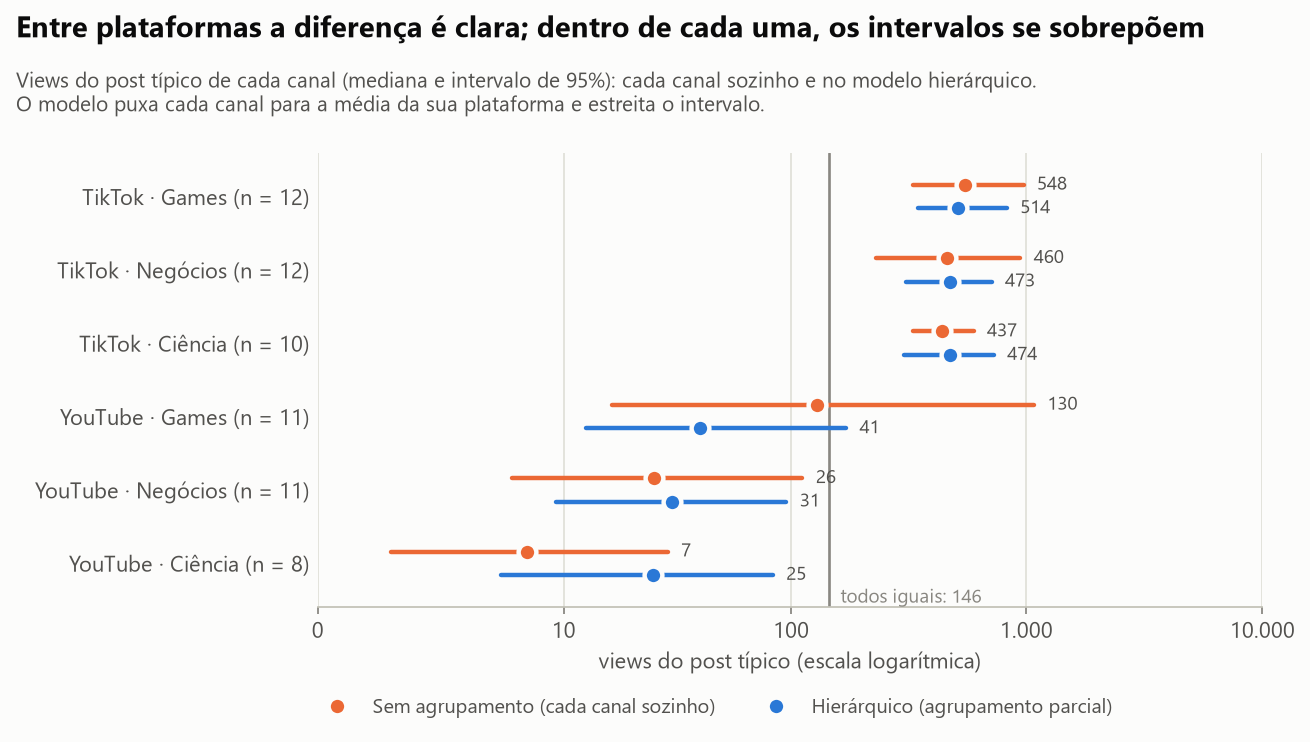

In [5]:
est = r["estimativas"]
formas = ["sem_agrupamento", "hierarquico", "agrupamento_total"]
quadro = pd.concat(
    {analise.NOME_DA_FORMA[f]: est[est["forma"] == f].set_index("canal")[["tipico", "tipico_inferior", "tipico_superior"]] for f in formas}, axis=1
).reindex(dados.CANAIS)
display(quadro.round(0))
display(r["encolhimento"])
figuras["estimativas"]

Sozinho, o YouTube · Games parece valer várias vezes o YouTube · Ciência, com intervalos enormes. O modelo hierárquico puxa os três canais do YouTube para perto um do outro (cerca de 80% do caminho até a média da plataforma) e estreita os intervalos. No TikTok os três canais já estavam juntos. O agrupamento total fica no meio do nada: não descreve nenhuma das duas plataformas.

## 3. O amostrador convergiu?

Quatro cadeias partindo de pontos espalhados. R-hat perto de 1 diz que elas contam a mesma história; o tamanho efetivo diz a quantas amostras independentes as cadeias equivalem. `tau` é o parâmetro mais difícil (é o que usa Metropolis), e por isso tem o menor tamanho efetivo.

In [6]:
display(r["diagnosticos"]["hierarquico"])
print("aceitação do Metropolis (tau):", round(float(r["principal"].posteriori.aceitacao_tau.mean()), 3))
display(pd.DataFrame(r["pior_diagnostico"]).T)

,media,mediana,inferior,superior,rhat,amostra_efetiva
theta · TikTok · Games,6.25,6.24,5.85,6.72,1.00,"9,783.36"
theta · TikTok · Negócios,6.16,6.16,5.73,6.57,1.00,"11,800.51"
theta · TikTok · Ciência,6.16,6.16,5.72,6.59,1.00,"13,301.98"
theta · YouTube · Games,3.77,3.73,2.62,5.15,1.00,"5,904.55"
theta · YouTube · Negócios,3.45,3.45,2.33,4.57,1.00,"14,586.45"
theta · YouTube · Ciência,3.22,3.26,1.79,4.44,1.00,"5,702.05"
mu · bloco 0,6.19,6.19,5.47,6.90,1.00,"15,003.24"
mu · bloco 1,3.48,3.48,2.36,4.63,1.00,"14,918.31"
sigma · grupo de dispersão 0,0.81,0.79,0.61,1.08,1.00,"8,067.06"
sigma · grupo de dispersão 1,2.57,2.54,1.96,3.40,1.00,"10,955.71"


aceitação do Metropolis (tau): 0.427


,maior_rhat,menor_amostra_efetiva
sem_agrupamento,1.00,"7,497.79"
agrupamento_total,1.00,"13,036.95"
hierarquico,1.00,"1,724.58"
por_plataforma,1.00,"8,536.44"
hierarquico_sem_plataforma,1.00,"2,573.72"
priori semi_cauchy,1.00,"1,738.97"
priori uniforme,1.00,"1,218.72"
tratamento: Só posts com 24 h ou mais,1.00,"1,552.56"
"tratamento: Todo jovem como piso, sem teto",1.00,"1,712.11"


## 4. Sensibilidade à priori de tau

Com seis canais (três por plataforma), há pouquíssima informação sobre o quanto os canais diferem entre si. O mesmo modelo, com três prioris razoáveis para `tau`:

,semi_normal,semi_cauchy,uniforme
priori,semi-normal(1),semi-Cauchy(1),"uniforme(0, 5)"
tau_priori_mediana,0.67,1.00,2.50
tau_priori_superior,2.24,25.33,4.88
tau_mediana,0.28,0.25,0.36
tau_inferior,0.01,0.01,0.01
tau_superior,1.34,1.41,2.35
"p_tau_menor_que_0,1",0.21,0.23,0.18
"p_tau_maior_que_0,5",0.29,0.26,0.38
rhat_de_tau,1.00,1.00,1.00
amostra_efetiva_de_tau,"1,724.58","1,738.97","1,218.72"


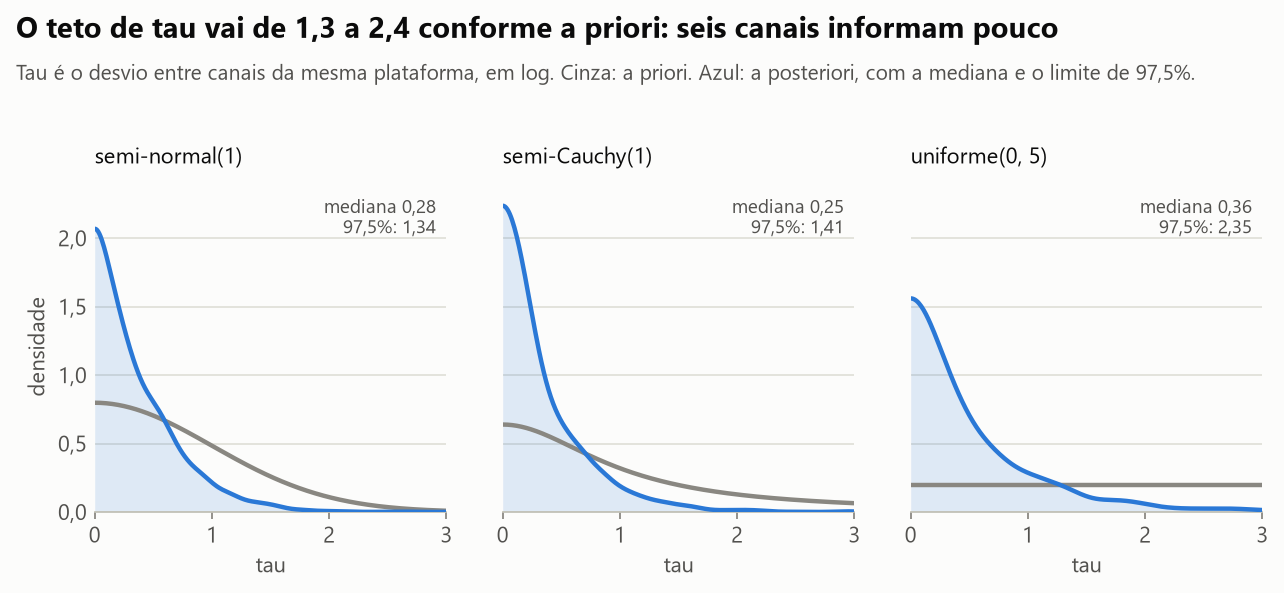

In [7]:
display(r["prioris"].T)
figuras["prioris_de_tau"]

A mediana de `tau` muda pouco, mas o limite superior quase dobra da semi-normal para a uniforme: os dados dizem que `tau` provavelmente é pequeno e não conseguem descartar que seja grande. A decisão (quem lidera e com que probabilidade) quase não muda entre as prioris.

## 5. Sensibilidade ao tratamento dos posts jovens

Aqui a conclusão muda mais.

In [8]:
display(r["jovens"].T)

,Jovem de 12 a 24 h entre o observado e 5x (principal),Só posts com 24 h ou mais,"Todo jovem como piso, sem teto"
posts,64,42,64
tau_mediana,0.28,0.23,0.24
sigma_tiktok,0.79,0.43,0.56
sigma_youtube,2.54,2.13,2.95
tiktok_sobre_youtube,14.99,29.47,10.05
lider,TikTok · Games,TikTok · Negócios,TikTok · Negócios
p_melhor_e_do_tiktok,1.00,1.00,0.99
p_melhor · TikTok · Games,0.47,0.08,0.29
p_melhor · TikTok · Negócios,0.26,0.71,0.55
p_melhor · TikTok · Ciência,0.27,0.21,0.15


A plataforma vence em qualquer tratamento. O canal líder dentro do TikTok, não: troca conforme os posts do último dia entram ou não. E o nível do YouTube varia por um fator de quatro a cinco. É a amostra pequena aparecendo: um dia de publicação muda a ordem.

## 6. Checagem preditiva a posteriori

O modelo ajustado gera dados parecidos com os reais? Simulam-se milhares de conjuntos de dados a partir da posteriori e compara-se a dispersão e a cauda com o observado nos posts maduros.

,observado,replicas_mediana,replicas_inferior,replicas_superior,p_preditivo
TikTok: desvio do log das views,0.44,0.80,0.52,1.20,1.00
TikTok: menor post (views),134.00,104.00,29.98,235.00,0.30
TikTok: maior post (views),643.00,"2,224.00",983.98,"7,736.07",1.00
YouTube: desvio do log das views,2.15,2.34,1.61,3.35,0.68
YouTube: parcela com até 5 views,0.60,0.25,0.05,0.50,0.01
YouTube: maior post (views),"1,196.00","3,429.50",292.97,"162,373.28",0.77


Só com os posts maduros no ajuste:


,observado,replicas_mediana,replicas_inferior,replicas_superior,p_preditivo
TikTok: desvio do log das views,0.44,0.45,0.28,0.68,0.57
TikTok: menor post (views),134.00,176.00,88.00,274.03,0.81
TikTok: maior post (views),643.00,990.00,624.97,"1,951.15",0.96
YouTube: desvio do log das views,2.15,1.92,1.28,2.83,0.29
YouTube: parcela com até 5 views,0.60,0.35,0.10,0.65,0.06
YouTube: maior post (views),"1,196.00",735.50,78.95,"20,902.20",0.37


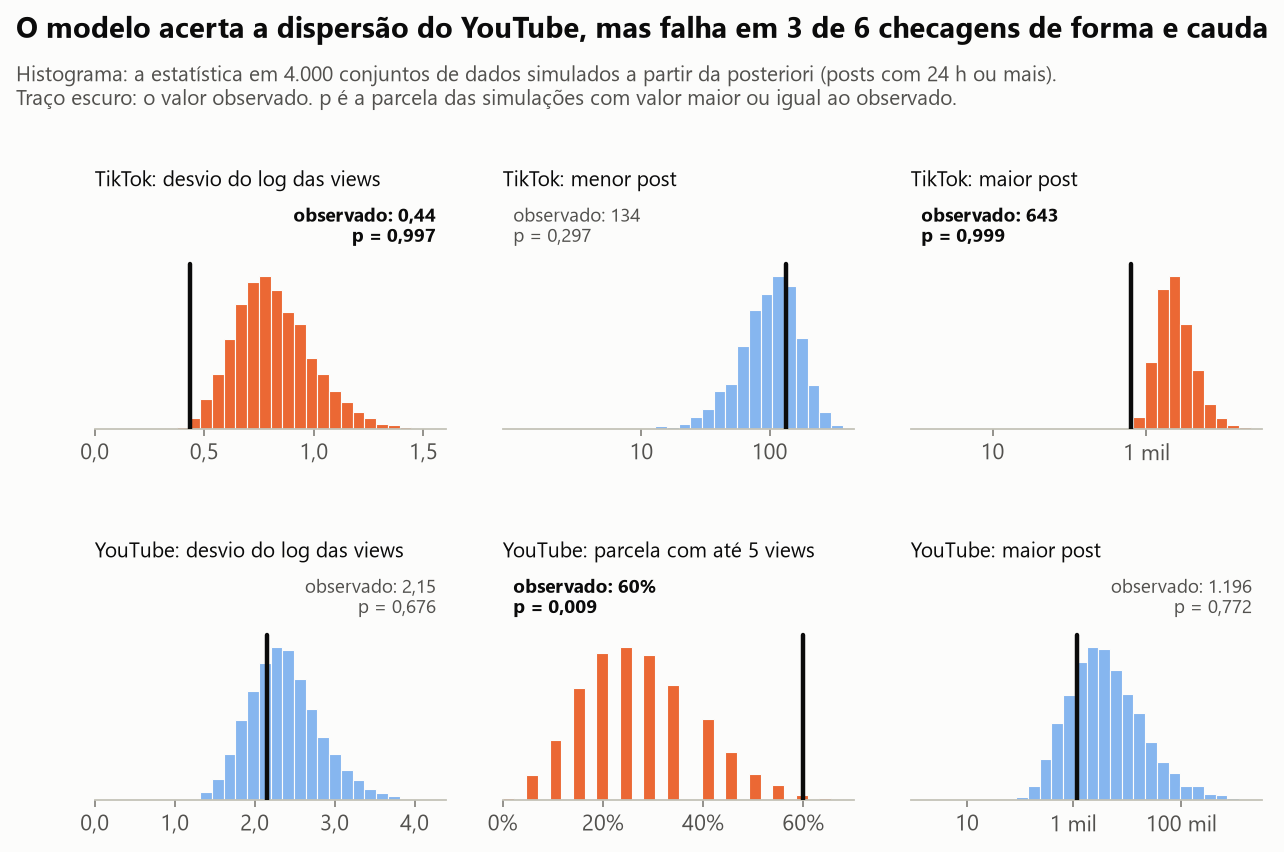

In [9]:
display(r["checagem"])
print("Só com os posts maduros no ajuste:")
display(r["checagem_so_maduros"])
figuras["checagem_preditiva"]

A dispersão do YouTube e os extremos dele passam. Três checagens falham: no TikTok o modelo espera mais dispersão e posts maiores do que os posts maduros mostram (um post jovem que ficou em 6 views infla o desvio, e os posts maduros batem num teto perto de 650 views), e no YouTube 60% dos posts ficam com até 5 views, mais do que uma normal em log produz. O modelo serve para comparar o centro dos canais; não serve para descrever a forma da distribuição.

## 7. Validação: qual forma prevê melhor um post que ficou de fora?

Duas validações. Na primeira, um corte sai por vez (com os posts dele nas duas plataformas) e os posts maduros desse corte são previstos. Na segunda, o modelo treina com a primeira metade dos posts maduros, por data, e prevê a segunda metade. O erro é o erro absoluto em log; a diferença para o hierárquico traz intervalo de 95% por bootstrap de cortes.

,erro_absoluto_medio,fator_de_erro,diferenca_de_erro_para_o_hierarquico,diferenca_de_erro_inferior,diferenca_de_erro_superior,log_densidade_media
Hierárquico (agrupamento parcial),1.19,3.29,0.00,0.00,0.00,-1.59
Uma média por plataforma,1.19,3.28,-0.00,-0.06,0.04,-1.56
Média crua do canal (linha de base),1.19,3.28,-0.00,-0.19,0.20,-1.90
Sem agrupamento (cada canal sozinho),1.19,3.28,-0.00,-0.20,0.21,-1.73
Hierárquico sem a plataforma,1.33,3.78,0.14,-0.01,0.29,-1.67
Agrupamento total (todos iguais),1.89,6.63,0.70,0.40,0.98,-2.28


{'treina_ate': '2026-11-08T12:00:00', 'posts_de_treino': 23, 'posts_de_teste': 19, 'posts_de_treino_por_canal_minimo': 3, 'posts_de_treino_por_canal_maximo': 4}


,erro_absoluto_medio,fator_de_erro,diferenca_de_erro_para_o_hierarquico,diferenca_de_erro_inferior,diferenca_de_erro_superior,log_densidade_media
Hierárquico (agrupamento parcial),1.05,2.85,0.00,0.00,0.00,-1.28
Uma média por plataforma,1.04,2.83,-0.01,-0.04,0.03,-1.28
Média crua do canal (linha de base),1.13,3.11,0.09,-0.14,0.30,-1.21
Sem agrupamento (cada canal sozinho),1.13,3.10,0.08,-0.14,0.29,-1.35
Hierárquico sem a plataforma,1.56,4.78,0.52,0.16,0.77,-1.50
Agrupamento total (todos iguais),2.15,8.59,1.10,0.78,1.34,-2.30


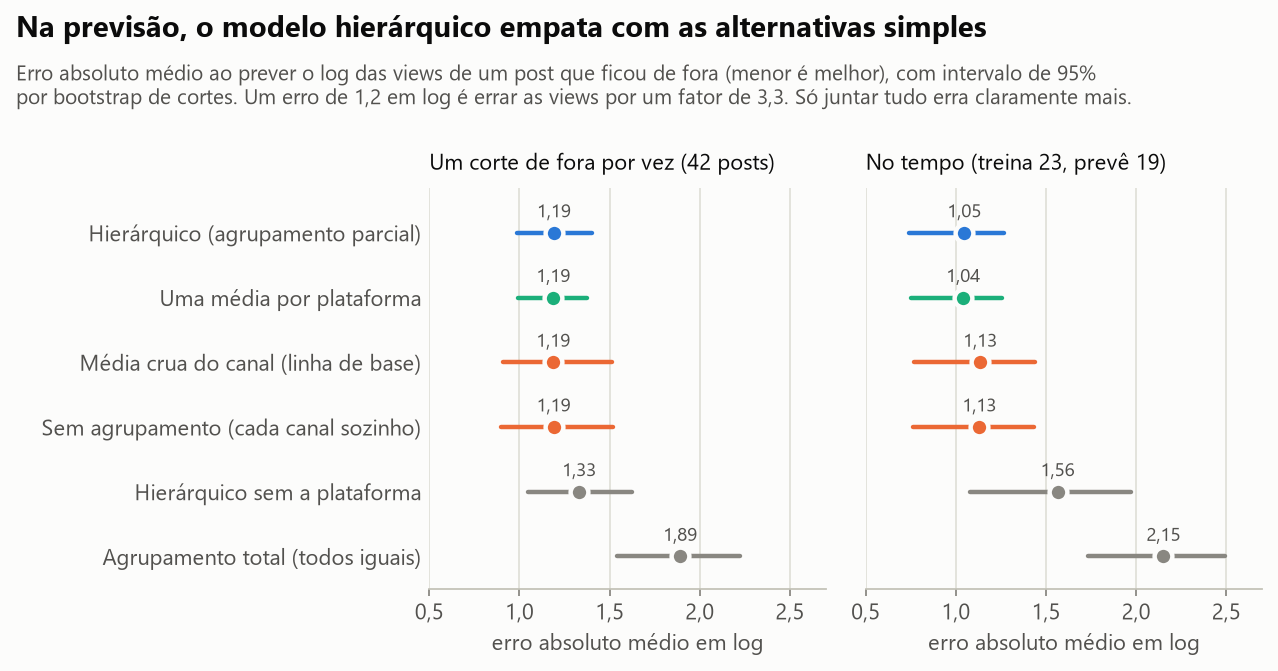

In [10]:
colunas = ["erro_absoluto_medio", "fator_de_erro", "diferenca_de_erro_para_o_hierarquico", "diferenca_de_erro_inferior", "diferenca_de_erro_superior", "log_densidade_media"]
ordem = ["hierarquico", "por_plataforma", "media_crua", "sem_agrupamento", "hierarquico_sem_plataforma", "agrupamento_total"]
display(r["validacao_cruzada"].loc[ordem, colunas].rename(index=analise.NOME_DA_FORMA))
print(r["info_do_tempo"])
display(r["validacao_no_tempo"].loc[ordem, colunas].rename(index=analise.NOME_DA_FORMA))
figuras["validacao"]

O modelo hierárquico **empata** com as alternativas simples: uma média por plataforma erra o mesmo, e a média crua do canal também (o intervalo da diferença inclui o zero nas duas validações). Quem perde com clareza é juntar tudo e ignorar a plataforma. O que o modelo hierárquico entrega a mais não é previsão de ponto: é a incerteza de cada canal e a probabilidade de cada um ser o melhor.

## 8. A decisão

In [11]:
d = r["decisao"]
display(pd.DataFrame({"P(ser o melhor)": d["p_melhor"], "views perdidas por post, em média, apostando nele": d["perda_esperada_por_post"]}))
print("P(o melhor canal é do TikTok):", round(d["p_melhor_e_do_tiktok"], 4))
print("post típico do TikTok sobre o do YouTube:", {k: round(v, 2) for k, v in d["tiktok_sobre_youtube"].items()})
print("dentro do TikTok, melhor sobre pior:", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in d["dentro_da_plataforma"]["tiktok"].items()})
print("P(melhor nicho, somando as duas plataformas):", {k: round(v, 3) for k, v in d["p_melhor_nicho"].items()})

,P(ser o melhor),"views perdidas por post, em média, apostando nele"
TikTok · Games,0.47,45.22
TikTok · Negócios,0.26,94.78
TikTok · Ciência,0.27,92.98
YouTube · Games,0.00,523.55
YouTube · Negócios,0.00,540.64
YouTube · Ciência,0.00,546.80


P(o melhor canal é do TikTok): 0.9993
post típico do TikTok sobre o do YouTube: {'fator': 14.99, 'inferior': 4.04, 'superior': 55.83, 'p_tiktok_maior': 1.0}
dentro do TikTok, melhor sobre pior: {'fator_melhor_sobre_pior': 1.28, 'inferior': 1.01, 'superior': 2.33, 'p_diferenca_menor_que_25_por_cento': 0.45, 'p_melhor_dentro_da_plataforma': [0.4715, 0.260375, 0.268125]}
P(melhor nicho, somando as duas plataformas): {'Games': 0.518, 'Negócios': 0.244, 'Ciência': 0.239}


A plataforma está decidida. O canal dentro do TikTok, não: o líder não chega a 50%, e a diferença entre o melhor e o pior canal do TikTok é pequena.

Um alerta sobre o objetivo. Tudo acima é o post típico (mediana). Se o objetivo fosse a soma de views, a conta seria `exp(theta + sigma²/2)`, que no YouTube é quase toda cauda extrapolada:

In [12]:
display(pd.DataFrame(r["media_no_modelo"]).T.round(2))

,media_implicada,inferior,superior,p_melhor
TikTok · Games,707.29,470.69,"1,265.41",0.16
TikTok · Negócios,650.03,426.21,"1,080.54",0.09
TikTok · Ciência,649.77,417.43,"1,119.85",0.09
YouTube · Games,"1,087.19",212.09,"17,676.61",0.39
YouTube · Negócios,790.26,138.47,"14,785.83",0.16
YouTube · Ciência,654.39,77.14,"12,879.77",0.11


Os intervalos do YouTube vão de cerca de cem a mais de dez mil views. Com esta amostra, a média de views do YouTube não é estimável; a decisão fica no post típico, e isso está declarado como limitação.

## 9. Quanto custa decidir cedo: simulação de alocação

Cada "mundo" é uma amostra da posteriori: um desempenho plausível para cada canal. Em cada mundo, três regras publicam os posts das próximas quatro semanas da agenda, uma de cada vez, começando do zero:

- **repartição igual** (a regra atual);
- **tudo no líder depois de N posts por canal** (a tentação);
- **amostragem de Thompson** (a cada post, sorteia um desempenho plausível de cada canal e publica no que saiu melhor).

O arrependimento é o que se deixou de ganhar, em views do post típico, por não publicar sempre no melhor canal daquele mundo.

{'semanas': 4, 'de': '2026-11-16', 'posts_na_agenda': 166, 'horizonte': 168}


,politica,parcela_perdida_do_ideal,arrependimento_medio,arrependimento_p10,arrependimento_mediano,arrependimento_p90,p_termina_em_canal_ruim,p_termina_na_plataforma_errada,p_perde_menos_que_thompson
igual,Repartição igual,0.53,"51,381.15","36,040.64","48,048.78","70,324.02",NaN,NaN,0.00
thompson,Amostragem de Thompson,0.12,"11,615.29","5,487.00","10,571.54","18,778.21",0.01,0.00,0.00
lider_1,Tudo no líder depois de 1 posts por canal,0.31,"30,388.64","1,559.92","10,695.77","87,439.19",0.40,0.26,0.50
lider_2,Tudo no líder depois de 2 posts por canal,0.22,"20,987.41","2,988.54","6,776.58","71,647.18",0.27,0.14,0.57
lider_3,Tudo no líder depois de 3 posts por canal,0.19,"18,433.35","4,420.40","8,062.71","55,506.57",0.22,0.10,0.54
lider_5,Tudo no líder depois de 5 posts por canal,0.18,"17,019.33","7,010.38","10,934.39","34,193.84",0.16,0.04,0.38
lider_10,Tudo no líder depois de 10 posts por canal,0.22,"21,725.81","13,633.32","19,162.81","32,736.21",0.09,0.01,0.06
lider_15,Tudo no líder depois de 15 posts por canal,0.31,"29,525.64","19,972.66","27,461.16","41,878.95",0.06,0.01,0.01


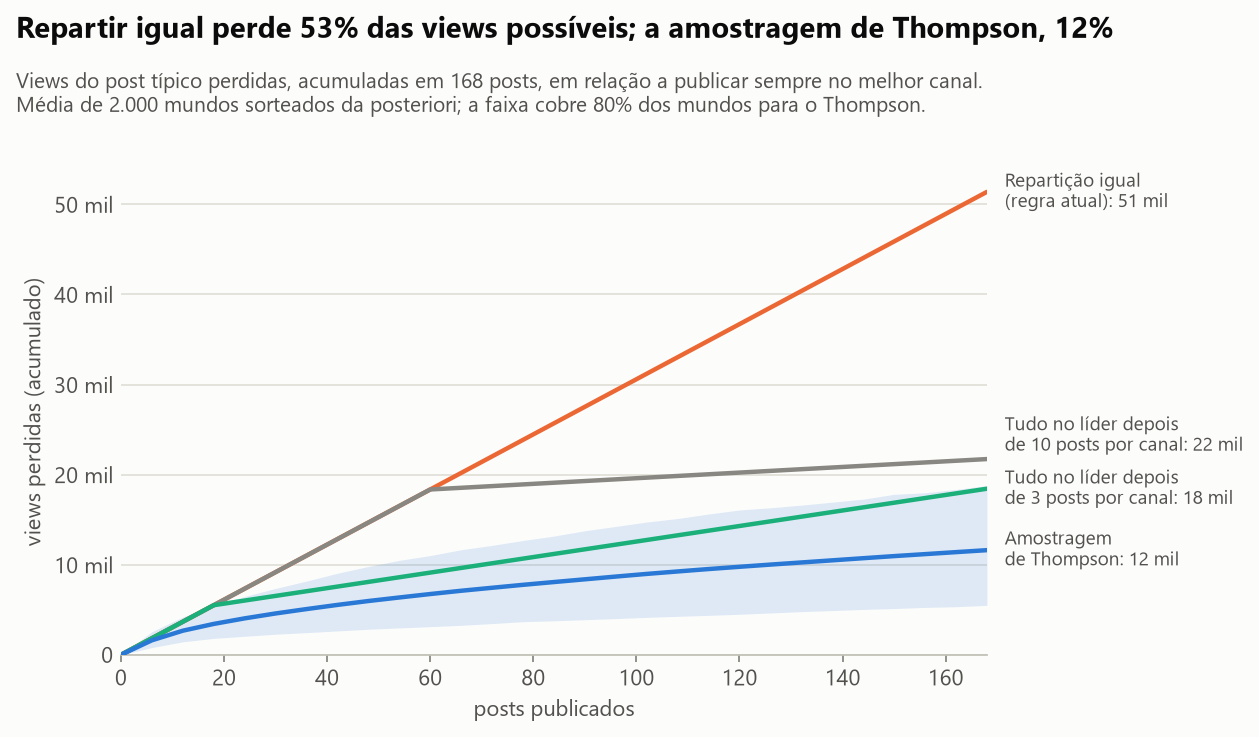

In [13]:
print(r["horizonte"])
sim = r["simulacao"]
display(sim[["politica", "parcela_perdida_do_ideal", "arrependimento_medio", "arrependimento_p10", "arrependimento_mediano", "arrependimento_p90", "p_termina_em_canal_ruim", "p_termina_na_plataforma_errada", "p_perde_menos_que_thompson"]])
figuras["arrependimento"]

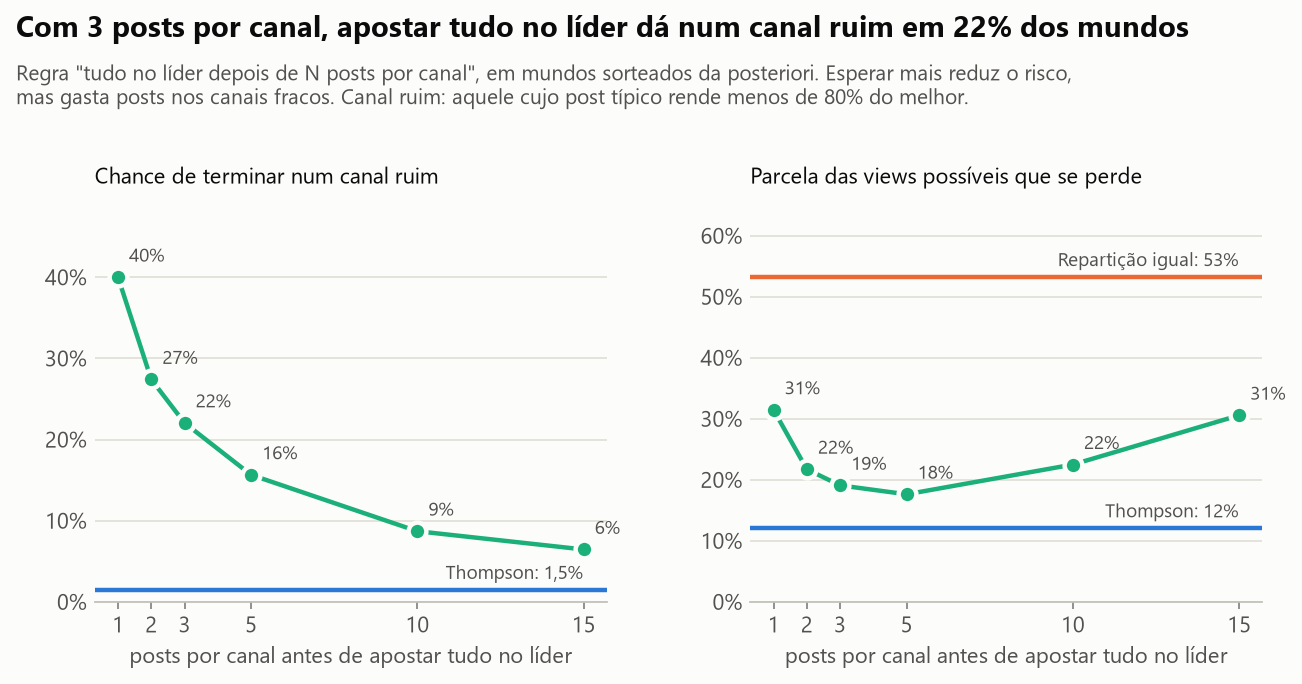

In [14]:
figuras["decidir_cedo"]

Três leituras:

1. Decidir cedo é uma aposta: na maioria dos mundos, apostar tudo no líder depois de 2 ou 3 posts por canal perde menos que o Thompson (veja a mediana e a última coluna). Mas em cerca de um a cada quatro ou cinco mundos a aposta termina num canal ruim, e aí a perda é várias vezes maior (veja o percentil 90). Na média, o Thompson ganha.
2. Esperar demais também custa: cada post gasto para "ter certeza" num canal fraco é perda garantida.
3. A repartição igual é a pior regra só se o esforço for transferível. Na operação real, o mesmo corte vai para as duas plataformas quase de graça; a escolha que custa é o nicho, e para o nicho os dados ainda não separam ninguém.

## 10. Onde este estudo falha

- 64 posts publicados em quatro dias: um único dia mudou o patamar do YouTube · Games, e o modelo supõe canais estáveis.
- O canal líder dentro do TikTok troca conforme o tratamento dos posts jovens.
- O modelo não reproduz a forma dos dados (três de seis checagens preditivas falham).
- O objetivo é o post típico; a soma de views, dominada pela cauda, não é estimável com esta amostra.
- `tau` é comum às duas plataformas e mal identificado com seis canais.
- A simulação sorteia os mundos da própria posteriori e herda todas as limitações acima.

O README traz a lista completa.